In [1]:
import pandas as pd
import numpy as np

# ---------------- LOAD DATA ----------------
df = pd.read_csv("forex_usd_inr_2007_to_present.csv")

# The first column is actually the Date column, rename it properly
df = df.rename(columns={df.columns[0]: "Date"})

# Convert Date column to proper datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Drop invalid rows if any occurred during shifting
df = df.dropna(subset=["Date"])

# Convert numeric columns safely
for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing values created during conversion
df = df.ffill().bfill()

# Set date as index
df = df.set_index("Date")

print(df.head())
print(df.dtypes)

# ---------------- CREATE REGIME-BASED SPLITS ----------------
df1 = df.loc[: "2010-12-31"]              # Pre-2011
df2 = df.loc["2011-01-01":"2019-12-31"]   # 2011–2019
df3 = df.loc["2020-01-01":"2021-12-31"]   # COVID period
df4 = df.loc["2022-01-01":]               # 2022 onward

# Print sizes
print("\nSizes of each segment:")
print("df1 (2007–2010):", len(df1))
print("df2 (2011–2019):", len(df2))
print("df3 (2020–2021):", len(df3))
print("df4 (2022–present):", len(df4))


                Close       High        Low       Open  Volume
Date                                                          
2007-01-01  44.215000  44.223999  44.040001  44.220001       0
2007-01-02  44.122002  44.220001  44.075001  44.212002       0
2007-01-03  44.111000  44.410000  44.085999  44.119999       0
2007-01-04  44.095001  44.480000  44.095001  44.119999       0
2007-01-05  44.139999  44.330002  44.095001  44.095001       0
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Sizes of each segment:
df1 (2007–2010): 1021
df2 (2011–2019): 2342
df3 (2020–2021): 523
df4 (2022–present): 1003


C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\2624355148.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [8]:
df = pd.read_csv("crude_oil_2007_to_present.csv")
df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(",","",regex=False), errors="coerce")

df = df.sort_values("Date").fillna(method="ffill").fillna(method="bfill")
df = df[["Date","Close"]].dropna().reset_index(drop=True)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_35752\2959239312.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_35752\2959239312.py:9: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.sort_values("Date").fillna(method="ffill").fillna(method="bfill")


In [9]:
df1 = df[df["Date"].dt.year <= 2011]
df2 = df[(df["Date"].dt.year > 2011) & (df["Date"].dt.year <= 2019)]
df3 = df[(df["Date"].dt.year >= 2020) & (df["Date"].dt.year <= 2022)]
df4 = df[df["Date"].dt.year > 2022]

splits = [
    ("2007–2011", df1),
    ("2011–2019", df2),
    ("2020–2022", df3),
    ("2022–Latest", df4)
]

In [10]:
import pandas as pd

df = pd.read_csv("crude_oil_2007_to_present.csv")
print(df.columns)


Index(['Price', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')


In [18]:
df.head()

,Price,Close,High,Low,Open,Volume
0,2007-01-03,58.31999969482422,60.970001220703125,57.720001220703125,60.95000076293945,248547
1,2007-01-04,55.59000015258789,58.58000183105469,55.38999938964844,58.349998474121094,324010
2,2007-01-05,56.310001373291016,56.400001525878906,54.900001525878906,55.40999984741211,250130
3,2007-01-08,56.09000015258789,57.720001220703125,55.099998474121094,56.2400016784668,298727
4,2007-01-09,55.63999938964844,56.20000076293945,53.880001068115234,56.119998931884766,333330


In [3]:
import pandas as pd
import numpy as np

# ---------------- LOAD DATA ----------------
df = pd.read_csv("gold_2007_to_present.csv")

# The first column is actually the Date column, rename it properly
df = df.rename(columns={df.columns[0]: "Date"})

# Convert Date column to proper datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Drop invalid rows if any occurred during shifting
df = df.dropna(subset=["Date"])

# Convert numeric columns safely
for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing values created during conversion
df = df.ffill().bfill()

# Set date as index
df = df.set_index("Date")

print(df.head())
print(df.dtypes)

# ---------------- CREATE REGIME-BASED SPLITS ----------------
df1 = df.loc[: "2010-12-31"]              # Pre-2011
df2 = df.loc["2011-01-01":"2019-12-31"]   # 2011–2019
df3 = df.loc["2020-01-01":"2021-12-31"]   # COVID period
df4 = df.loc["2022-01-01":]               # 2022 onward

# Print sizes
print("\nSizes of each segment:")
print("df1 (2007–2010):", len(df1))
print("df2 (2011–2019):", len(df2))
print("df3 (2020–2021):", len(df3))
print("df4 (2022–present):", len(df4))


                 Close        High         Low        Open  Volume
Date                                                              
2007-01-02  635.200012  635.200012  635.200012  635.200012      17
2007-01-03  627.099976  640.400024  628.500000  640.400024      38
2007-01-04  623.900024  624.500000  624.500000  624.500000       4
2007-01-05  604.900024  623.700012  617.299988  623.700012     531
2007-01-08  607.500000  607.500000  607.500000  607.500000    1000
Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

Sizes of each segment:
df1 (2007–2010): 1009
df2 (2011–2019): 2261
df3 (2020–2021): 505
df4 (2022–present): 970


C:\Users\ASUS\AppData\Local\Temp\ipykernel_8528\3444150856.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Dictionary to store all results
results = {
    "XGBoost": {},
    "CatBoost": {},
    "TCN": {},
    "ARIMA": {},
    "SARIMA": {},
    "BiLSTM": {},
    "ConvLSTM": {}
}

datasets = {
    "df1": df1,
    "df2": df2,
    "df3": df3,
    "df4": df4
}

def prepare_data(df):
    df = df.copy()

 

    # Multi-output targets
    y = df[["High", "Low"]]           # predicting both
    X = df.drop(["High", "Low"], axis=1)

    return train_test_split(X, y, test_size=0.2, random_state=42)


In [4]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

def evaluate_model(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Avoid divide-by-zero in MAPE
    non_zero_idx = y_true != 0
    mape = np.mean(np.abs((y_true[non_zero_idx] - y_pred[non_zero_idx]) / y_true[non_zero_idx])) * 100

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)

    return {
        "MAPE": mape,
        "RMSE": rmse,
        "R2": r2,
        "MAE": mae
    }


In [5]:
from xgboost import XGBRegressor

for name, df in datasets.items():
    X_train, X_test, y_train, y_test = prepare_data(df)

    model = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8
    )
    
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    results["XGBoost"][name] = {
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "R2": r2_score(y_test, preds)
    }

results["XGBoost"]


{'df1': {'RMSE': 6.168343840023817, 'R2': 0.9990535974502563},
 'df2': {'RMSE': 5.959100242646057, 'R2': 0.9990144968032837},
 'df3': {'RMSE': 9.799600273855242, 'R2': 0.9896398782730103},
 'df4': {'RMSE': 17.19842071379893, 'R2': 0.9991862773895264}}

In [6]:
from xgboost import XGBRegressor

for name, df in datasets.items():
    X_train, X_test, y_train, y_test = prepare_data(df)

    model = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6
    )

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    results["XGBoost"][name] = evaluate_model(y_test, preds)
    


In [7]:
results["XGBoost"]

{'df1': {'MAPE': 0.4716350091166879,
  'RMSE': 6.169793458524585,
  'R2': 0.9990533986703038,
  'MAE': 4.436369338838184},
 'df2': {'MAPE': 0.2803753814185316,
  'RMSE': 5.858574699472529,
  'R2': 0.9990476864785867,
  'MAE': 3.9529253220716054},
 'df3': {'MAPE': 0.33915437582803865,
  'RMSE': 9.51672049180083,
  'R2': 0.9902301251852028,
  'MAE': 5.918978549466276},
 'df4': {'MAPE': 0.3495529318804467,
  'RMSE': 18.9835426359201,
  'R2': 0.9990070718352657,
  'MAE': 8.84984816718347}}

In [8]:
from statsmodels.tsa.arima.model import ARIMA

for name, df in datasets.items():
    y = df["High"]  # choose High or Low separately

    train_size = int(len(y) * 0.8)
    train, test = y[:train_size], y[train_size:]

    model = ARIMA(train, order=(2,1,2))
    model_fit = model.fit()
    preds = model_fit.forecast(len(test))

    results["ARIMA"][name] = evaluate_model(test, preds)


d:\Anacondaa\envs\tfenv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
d:\Anacondaa\envs\tfenv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
d:\Anacondaa\envs\tfenv\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
d:\Anacondaa\envs\tfenv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
d:\Anacondaa\envs\tf

In [9]:
results["ARIMA"]

{'df1': {'MAPE': 10.545246377799621,
  'RMSE': 163.67499796650466,
  'R2': -2.3108132735427467,
  'MAE': 138.48302705491383},
 'df2': {'MAPE': 6.273673198732937,
  'RMSE': 105.37688196699078,
  'R2': -0.010481944895258888,
  'MAE': 85.51033689102611},
 'df3': {'MAPE': 2.7951623016531237,
  'RMSE': 57.830059938411516,
  'R2': -3.0894167596476496,
  'MAE': 50.64446880873578},
 'df4': {'MAPE': 15.45336017495487,
  'RMSE': 658.6615141525367,
  'R2': -2.48595968890244,
  'MAE': 556.2142402588826}}

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae,3))
    print("RMSE:",  round(rmse,3))
    print("R2  :",  round(r2,3))
    print("MAPE:", round(mape,2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD BiLSTM MODEL ----------------
def build_bilstm(input_shape):
    model = Sequential([

        Bidirectional(LSTM(96, return_sequences=True), input_shape=input_shape),
        Dropout(0.25),

        Bidirectional(LSTM(64, return_sequences=False)),
        Dropout(0.25),

        Dense(32, activation='relu'),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model


# ---------------- MAIN FUNCTION ----------------
def run_BiLSTM(df, name):

    print(f"\n================ BiLSTM for {name} ================")

    # Features and target
    X = df[['Open','High','Low','Close']].values
    y = df[['High','Low']].values

    seq_len = 25
    train_size = max(int(len(df)*0.85), seq_len+3)
    train_size = min(train_size, len(df)-2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Sequence creation
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Adaptive batch size
    batch = 16 if len(X_train)>50 else 4

    model = build_bilstm((seq_len, X_train.shape[2]))

    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=batch,
        validation_data=(X_test, y_test) if len(X_test)>1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Prediction
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:,0], pred[:,1]
    true_high, true_low = y_true[:,0], y_true[:,1]

    m1 = metrics(true_high, pred_high, f"BiLSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"BiLSTM {name} Low")

    return (m1, m2)


In [12]:
# ================= RUN BILSTM ON ALL DATASETS ================= #

# df1, df2, df3, df4 must already be loaded before running this cell.

print("\n\n====== RUNNING BiLSTM ON ALL DATASETS ======\n")

results_bilstm = {}

for df, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training BiLSTM for {name} -----")
    try:
        res = run_BiLSTM(df, name)
        results_bilstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL BiLSTM RESULTS =============\n")
results_bilstm




====== RUNNING BiLSTM ON ALL DATASETS ======



----- Training BiLSTM for DF1 -----

================ BiLSTM for DF1 ================


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - loss: 0.0939 - val_loss: 0.2932 - learning_rate: 0.0010
Epoch 2/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0418 - val_loss: 0.1635 - learning_rate: 0.0010
Epoch 3/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0318 - val_loss: 0.2034 - learning_rate: 0.0010
Epoch 4/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0318 - val_loss: 0.1537 - learning_rate: 0.0010
Epoch 5/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0236 - val_loss: 0.2159 - learning_rate: 0.0010
Epoch 6/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0260 - val_loss: 0.1405 - learning_rate: 0.0010
Epoch 7/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0201 - val_loss: 0.1089 - learning_rate: 0.0010
Epoch 8/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0210 - val_loss: 0.1263 - learning_rate: 0.0010
Epoch 9/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0190 - val_loss: 0.1307 - learning_rate: 0.0010
Epoch 10/60
52/52 ━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.0661 - val_loss: 0.0096 - learning_rate: 0.0010
Epoch 2/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0245 - val_loss: 0.0068 - learning_rate: 0.0010
Epoch 3/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0221 - val_loss: 0.0112 - learning_rate: 0.0010
Epoch 4/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0188 - val_loss: 0.0074 - learning_rate: 0.0010
Epoch 5/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0195 - val_loss: 0.0057 - learning_rate: 0.0010
Epoch 6/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0166 - val_loss: 0.0067 - learning_rate: 0.0010
Epoch 7/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0150 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 8/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0149 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 9/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0147 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 10/60


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.2974 - val_loss: 0.0508 - learning_rate: 0.0010
Epoch 2/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1518 - val_loss: 0.0383 - learning_rate: 0.0010
Epoch 3/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1064 - val_loss: 0.0446 - learning_rate: 0.0010
Epoch 4/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.1046 - val_loss: 0.0330 - learning_rate: 0.0010
Epoch 5/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0831 - val_loss: 0.0260 - learning_rate: 0.0010
Epoch 6/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0766 - val_loss: 0.0262 - learning_rate: 0.0010
Epoch 7/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0736 - val_loss: 0.0241 - learning_rate: 0.0010
Epoch 8/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0698 - val_loss: 0.0229 - learning_rate: 0.0010
Epoch 9/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0644 - val_loss: 0.0234 - learning_rate: 0.0010
Epoch 10/60
26/26 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.1840 - val_loss: 2.0882 - learning_rate: 0.0010
Epoch 2/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0306 - val_loss: 1.5924 - learning_rate: 0.0010
Epoch 3/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0214 - val_loss: 1.0394 - learning_rate: 0.0010
Epoch 4/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0195 - val_loss: 1.1359 - learning_rate: 0.0010
Epoch 5/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0204 - val_loss: 0.9566 - learning_rate: 0.0010
Epoch 6/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0167 - val_loss: 0.8160 - learning_rate: 0.0010
Epoch 7/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0199 - val_loss: 0.9148 - learning_rate: 0.0010
Epoch 8/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0167 - val_loss: 0.6896 - learning_rate: 0.0010
Epoch 9/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0130 - val_loss: 0.6708 - learning_rate: 0.0010
Epoch 10/60
50/50 ━━━━━━━━━━━━━━━━━━━

{'DF1': {'High': {'MAE': 30.46076322856702,
   'RMSE': 38.915283402525596,
   'R2': 0.7491573512043591,
   'MAPE': 2.2766183582993036},
  'Low': {'MAE': 29.05877765856291,
   'RMSE': 37.20260080505371,
   'R2': 0.751991672791098,
   'MAPE': 2.1932237588457135}},
 'DF2': {'High': {'MAE': 7.15313720703125,
   'RMSE': 9.479759553167543,
   'R2': 0.9928868142864699,
   'MAPE': 0.5249245288126392},
  'Low': {'MAE': 6.844464111328125,
   'RMSE': 8.860936209688656,
   'R2': 0.9933975066578595,
   'MAPE': 0.5062199860495765}},
 'DF3': {'High': {'MAE': 12.0676124974301,
   'RMSE': 15.614294654878345,
   'R2': 0.7340260505839157,
   'MAPE': 0.6704887730170865},
  'Low': {'MAE': 11.770662006578945,
   'RMSE': 16.378186017589826,
   'R2': 0.7457722029293776,
   'MAPE': 0.6600939194652367}},
 'DF4': {'High': {'MAE': 147.50923219445633,
   'RMSE': 225.01494643451656,
   'R2': 0.4283220247967432,
   'MAPE': 3.8383636208223817},
  'Low': {'MAE': 150.03586358893406,
   'RMSE': 234.96671285167207,
   'R

In [13]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tcn import TCN


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae,3))
    print("RMSE:",  round(rmse,3))
    print("R2  :",  round(r2,3))
    print("MAPE:", round(mape,2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD TCN MODEL ----------------
def build_tcn(input_shape):
    model = Sequential([

        TCN(nb_filters=64,
            kernel_size=3,
            dilations=[1, 2, 4, 8, 16],
            dropout_rate=0.25,
            return_sequences=False,
            activation='relu',
            input_shape=input_shape),

        Dense(32, activation='relu'),
        Dropout(0.25),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model


# ---------------- MAIN TCN FUNCTION ----------------
def run_TCN(df, name):

    print(f"\n================ TCN for {name} ================")

    # Features and target
    X = df[['Open','High','Low','Close']].values
    y = df[['High','Low']].values

    seq_len = 25
    train_size = max(int(len(df)*0.85), seq_len+3)
    train_size = min(train_size, len(df)-2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Sequence creation
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len

    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    batch = 16 if len(X_train)>50 else 4

    model = build_tcn((seq_len, X_train.shape[2]))

    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=batch,
        validation_data=(X_test, y_test) if len(X_test)>1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Prediction
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:,0], pred[:,1]
    true_high, true_low = y_true[:,0], y_true[:,1]

    m1 = metrics(true_high, pred_high, f"TCN {name} High")
    m2 = metrics(true_low,  pred_low,  f"TCN {name} Low")

    return (m1, m2)


In [14]:
results_tcn = {}

for df, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training TCN for {name} -----")
    try:
        res = run_TCN(df, name)
        results_tcn[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

results_tcn




----- Training TCN for DF1 -----

================ TCN for DF1 ================


d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)



Epoch 1/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 16.3546 - val_loss: 2.0146 - learning_rate: 0.0010
Epoch 2/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.5556 - val_loss: 2.4925 - learning_rate: 0.0010
Epoch 3/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9944 - val_loss: 2.5885 - learning_rate: 0.0010
Epoch 4/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6687 - val_loss: 1.9747 - learning_rate: 0.0010
Epoch 5/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5886 - val_loss: 1.8005 - learning_rate: 0.0010
Epoch 6/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5301 - val_loss: 1.0861 - learning_rate: 0.0010
Epoch 7/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4075 - val_loss: 0.7277 - learning_rate: 0.0010
Epoch 8/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4202 - val_loss: 0.9743 - learning_rate: 0.0010
Epoch 9/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3855 - val_loss: 0.7508 - learning_rate: 0.0010
Epoch 10/60
52/52 ━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 6.1755 - val_loss: 0.1328 - learning_rate: 0.0010
Epoch 2/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.7578 - val_loss: 0.0707 - learning_rate: 0.0010
Epoch 3/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4845 - val_loss: 0.0514 - learning_rate: 0.0010
Epoch 4/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3667 - val_loss: 0.0564 - learning_rate: 0.0010
Epoch 5/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.3099 - val_loss: 0.0497 - learning_rate: 0.0010
Epoch 6/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2737 - val_loss: 0.0486 - learning_rate: 0.0010
Epoch 7/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2264 - val_loss: 0.0452 - learning_rate: 0.0010
Epoch 8/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2265 - val_loss: 0.0417 - learning_rate: 0.0010
Epoch 9/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2101 - val_loss: 0.0179 - learning_rate: 0.0010
Epoch 10/60
119/119 

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 15.1176 - val_loss: 0.0851 - learning_rate: 0.0010
Epoch 2/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.7182 - val_loss: 0.0632 - learning_rate: 0.0010
Epoch 3/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.2159 - val_loss: 0.0527 - learning_rate: 0.0010
Epoch 4/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.9966 - val_loss: 0.0571 - learning_rate: 0.0010
Epoch 5/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.8161 - val_loss: 0.0551 - learning_rate: 0.0010
Epoch 6/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5826 - val_loss: 0.0504 - learning_rate: 0.0010
Epoch 7/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5640 - val_loss: 0.0487 - learning_rate: 0.0010
Epoch 8/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4421 - val_loss: 0.0458 - learning_rate: 0.0010
Epoch 9/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4576 - val_loss: 0.0435 - learning_rate: 0.0010
Epoch 10/60
26/26 ━━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Epoch 1/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 14.4681 - val_loss: 7.8828 - learning_rate: 0.0010
Epoch 2/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.5346 - val_loss: 8.5461 - learning_rate: 0.0010
Epoch 3/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8364 - val_loss: 8.5883 - learning_rate: 0.0010
Epoch 4/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.6412 - val_loss: 6.5734 - learning_rate: 0.0010
Epoch 5/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6267 - val_loss: 3.0923 - learning_rate: 0.0010
Epoch 6/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4865 - val_loss: 3.3288 - learning_rate: 0.0010
Epoch 7/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3987 - val_loss: 3.0167 - learning_rate: 0.0010
Epoch 8/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3521 - val_loss: 4.0243 - learning_rate: 0.0010
Epoch 9/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3214 - val_loss: 2.9893 - learning_rate: 0.0010
Epoch 10/60
50/50 ━━━━━━━━

{'DF1': {'High': {'MAE': 161.80542714972245,
   'RMSE': 165.7310266710504,
   'R2': -3.5495519076445587,
   'MAPE': 12.392682067859255},
  'Low': {'MAE': 68.95254677220395,
   'RMSE': 73.94203889429949,
   'R2': 0.02027880784980629,
   'MAPE': 5.325821772203776}},
 'DF2': {'High': {'MAE': 13.820647475298713,
   'RMSE': 18.240618591944713,
   'R2': 0.9736640718592184,
   'MAPE': 1.0177803892442387},
  'Low': {'MAE': 13.325980152803309,
   'RMSE': 17.65342257961863,
   'R2': 0.9737936470180917,
   'MAPE': 0.9718097214162811}},
 'DF3': {'High': {'MAE': 13.333510549444895,
   'RMSE': 16.954808731828326,
   'R2': 0.6863970418863357,
   'MAPE': 0.7422400327412586},
  'Low': {'MAE': 14.036670885587984,
   'RMSE': 17.06303180820282,
   'R2': 0.724066877034405,
   'MAPE': 0.7885445238418651}},
 'DF4': {'High': {'MAE': 341.1047981993793,
   'RMSE': 362.55477263934074,
   'R2': -0.48414379342867764,
   'MAPE': 9.465147449744386},
  'Low': {'MAE': 495.82119876391266,
   'RMSE': 512.7052318888528,


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau



# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)



# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- BUILD LSTM MODEL ----------------
def build_lstm(input_shape):

    model = Sequential([

        LSTM(96, return_sequences=True, input_shape=input_shape),
        Dropout(0.25),

        LSTM(64, return_sequences=False),
        Dropout(0.25),

        Dense(32, activation='relu'),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN FUNCTION ----------------
def run_LSTM(df, name):

    print(f"\n================ LSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Adaptive batch size
    batch_size = 16 if len(X_train) > 50 else 4

    # Build model
    model = build_lstm((seq_len, X_train.shape[2]))

    # Callbacks
    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train
    model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=batch_size,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Prediction
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"LSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"LSTM {name} Low")

    return (m1, m2)



# ================= RUN LSTM ON ALL DATASETS ================= #

print("\n\n====== RUNNING LSTM ON ALL DATASETS ======\n")

results_lstm = {}

# df1, df2, df3, df4 must already be defined
for df, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training LSTM for {name} -----")
    try:
        res = run_LSTM(df, name)
        results_lstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL LSTM RESULTS =============\n")
results_lstm




====== RUNNING LSTM ON ALL DATASETS ======



----- Training LSTM for DF1 -----

================ LSTM for DF1 ================
Epoch 1/60


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.1669 - val_loss: 0.4689 - learning_rate: 0.0010
Epoch 2/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0449 - val_loss: 0.4615 - learning_rate: 0.0010
Epoch 3/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0406 - val_loss: 0.4098 - learning_rate: 0.0010
Epoch 4/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0331 - val_loss: 0.2023 - learning_rate: 0.0010
Epoch 5/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0346 - val_loss: 0.3300 - learning_rate: 0.0010
Epoch 6/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0317 - val_loss: 0.4005 - learning_rate: 0.0010
Epoch 7/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0308 - val_loss: 0.1467 - learning_rate: 0.0010
Epoch 8/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0257 - val_loss: 0.1202 - learning_rate: 0.0010
Epoch 9/60
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0260 - val_loss: 0.1954 - learning_rate: 0.0010
Epoch 10/60
52/52 ━━━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.1022 - val_loss: 0.0093 - learning_rate: 0.0010
Epoch 2/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0326 - val_loss: 0.0082 - learning_rate: 0.0010
Epoch 3/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0299 - val_loss: 0.0067 - learning_rate: 0.0010
Epoch 4/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0251 - val_loss: 0.0058 - learning_rate: 0.0010
Epoch 5/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0243 - val_loss: 0.0062 - learning_rate: 0.0010
Epoch 6/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0205 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 7/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0193 - val_loss: 0.0059 - learning_rate: 0.0010
Epoch 8/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0202 - val_loss: 0.0061 - learning_rate: 0.0010
Epoch 9/60
119/119 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0185 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 10/60
119/119 ━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.3256 - val_loss: 0.0607 - learning_rate: 0.0010
Epoch 2/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1365 - val_loss: 0.0467 - learning_rate: 0.0010
Epoch 3/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1277 - val_loss: 0.0414 - learning_rate: 0.0010
Epoch 4/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1110 - val_loss: 0.0312 - learning_rate: 0.0010
Epoch 5/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1012 - val_loss: 0.0338 - learning_rate: 0.0010
Epoch 6/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0972 - val_loss: 0.0342 - learning_rate: 0.0010
Epoch 7/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0913 - val_loss: 0.0258 - learning_rate: 0.0010
Epoch 8/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0867 - val_loss: 0.0265 - learning_rate: 0.0010
Epoch 9/60
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0868 - val_loss: 0.0257 - learning_rate: 0.0010
Epoch 10/60
26/26 ━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.1660 - val_loss: 2.0764 - learning_rate: 0.0010
Epoch 2/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0322 - val_loss: 1.3791 - learning_rate: 0.0010
Epoch 3/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0321 - val_loss: 1.1085 - learning_rate: 0.0010
Epoch 4/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0251 - val_loss: 1.0626 - learning_rate: 0.0010
Epoch 5/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0281 - val_loss: 1.1118 - learning_rate: 0.0010
Epoch 6/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0228 - val_loss: 0.9118 - learning_rate: 0.0010
Epoch 7/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0250 - val_loss: 0.9922 - learning_rate: 0.0010
Epoch 8/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0186 - val_loss: 0.6893 - learning_rate: 0.0010
Epoch 9/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0175 - val_loss: 0.5758 - learning_rate: 0.0010
Epoch 10/60
50/50 ━━━━━━━━━━━━━━━━━━━━

{'DF1': {'High': {'MAE': 27.711849011872943,
   'RMSE': 36.612216197810056,
   'R2': 0.7779693044472344,
   'MAPE': 2.0616771150482345},
  'Low': {'MAE': 30.440773411800986,
   'RMSE': 40.23127150610587,
   'R2': 0.7099671594284663,
   'MAPE': 2.2806980065377926}},
 'DF2': {'High': {'MAE': 7.8130722943474264,
   'RMSE': 10.150959378588546,
   'R2': 0.991843878562979,
   'MAPE': 0.5755689500424426},
  'Low': {'MAE': 7.669440056295956,
   'RMSE': 9.802478042318493,
   'R2': 0.9919198298129385,
   'MAPE': 0.5685337544567696}},
 'DF3': {'High': {'MAE': 11.049513967413658,
   'RMSE': 14.407605987057911,
   'R2': 0.7735470372475217,
   'MAPE': 0.6143578783479722},
  'Low': {'MAE': 11.226690995065793,
   'RMSE': 14.906082387087272,
   'R2': 0.7894193460372172,
   'MAPE': 0.6308971878889665}},
 'DF4': {'High': {'MAE': 159.1779651380565,
   'RMSE': 244.28554198659765,
   'R2': 0.32621047446654816,
   'MAPE': 4.137783062405376},
  'Low': {'MAE': 167.80884959599743,
   'RMSE': 262.3248743348272,


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ConvLSTM2D, Dropout, Flatten, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau



# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)



# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- BUILD ConvLSTM MODEL ----------------
def build_convlstm(input_shape):

    model = Sequential([

        ConvLSTM2D(
            filters=64,
            kernel_size=(1, 2),
            return_sequences=True,
            activation='tanh',
            padding='same',
            input_shape=input_shape
        ),
        Dropout(0.25),

        ConvLSTM2D(
            filters=32,
            kernel_size=(1, 2),
            return_sequences=False,
            activation='tanh',
            padding='same'
        ),
        Dropout(0.25),

        Flatten(),

        Dense(64, activation='relu'),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN FUNCTION ----------------
def run_ConvLSTM(df, name):

    print(f"\n================ ConvLSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge for sequence creation
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Split into train/test
    split = train_size - seq_len
    X_train_seq, X_test_seq = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # ConvLSTM requires 5D input: (batch, seq_len, spatial_x, spatial_y, channels)
    X_train = X_train_seq.reshape(-1, seq_len, 1, X_train_raw.shape[1], 1)
    X_test  = X_test_seq.reshape(-1, seq_len, 1, X_train_raw.shape[1], 1)

    # Adaptive batch size
    batch_size = 8 if len(X_train) > 50 else 2

    # Build model
    model = build_convlstm((seq_len, 1, X_train_raw.shape[1], 1))

    # Callbacks
    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train model
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=batch_size,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"ConvLSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"ConvLSTM {name} Low")

    return (m1, m2)



# ================= RUN ConvLSTM ON ALL DATASETS ================= #
print("\n\n====== RUNNING ConvLSTM ON ALL DATASETS ======\n")

results_convlstm = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training ConvLSTM for {name} -----")
    try:
        res = run_ConvLSTM(df_regime, name)
        results_convlstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL ConvLSTM RESULTS =============\n")
results_convlstm




====== RUNNING ConvLSTM ON ALL DATASETS ======



----- Training ConvLSTM for DF1 -----

================ ConvLSTM for DF1 ================
Epoch 1/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


104/104 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0931 - val_loss: 0.2053 - learning_rate: 0.0010
Epoch 2/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0364 - val_loss: 0.0807 - learning_rate: 0.0010
Epoch 3/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0314 - val_loss: 0.1678 - learning_rate: 0.0010
Epoch 4/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0269 - val_loss: 0.3695 - learning_rate: 0.0010
Epoch 5/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0228 - val_loss: 0.1714 - learning_rate: 0.0010
Epoch 6/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0209 - val_loss: 0.0512 - learning_rate: 5.0000e-04
Epoch 7/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0173 - val_loss: 0.0718 - learning_rate: 5.0000e-04
Epoch 8/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0181 - val_loss: 0.0729 - learning_rate: 5.0000e-04
Epoch 9/50
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0186 - val_loss: 0.0164 - learning_rate: 5.0000e

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


237/237 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - loss: 0.0609 - val_loss: 0.0097 - learning_rate: 0.0010
Epoch 2/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0246 - val_loss: 0.0063 - learning_rate: 0.0010
Epoch 3/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0216 - val_loss: 0.0053 - learning_rate: 0.0010
Epoch 4/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0178 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 5/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0175 - val_loss: 0.0056 - learning_rate: 0.0010
Epoch 6/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0172 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 7/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0136 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 8/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0123 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 9/50
237/237 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0121 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 10/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.2590 - val_loss: 0.0605 - learning_rate: 0.0010
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1134 - val_loss: 0.0411 - learning_rate: 0.0010
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1078 - val_loss: 0.0361 - learning_rate: 0.0010
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0955 - val_loss: 0.0308 - learning_rate: 0.0010
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0835 - val_loss: 0.0289 - learning_rate: 0.0010
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0840 - val_loss: 0.0257 - learning_rate: 0.0010
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0794 - val_loss: 0.0236 - learning_rate: 0.0010
Epoch 8/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0709 - val_loss: 0.0227 - learning_rate: 0.0010
Epoch 9/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0650 - val_loss: 0.0291 - learning_rate: 0.0010
Epoch 10/50
51/51 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 0.0988 - val_loss: 0.9628 - learning_rate: 0.0010
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0256 - val_loss: 0.8518 - learning_rate: 0.0010
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0210 - val_loss: 0.5132 - learning_rate: 0.0010
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0191 - val_loss: 0.1768 - learning_rate: 0.0010
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0167 - val_loss: 0.1705 - learning_rate: 0.0010
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0155 - val_loss: 0.4799 - learning_rate: 0.0010
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0181 - val_loss: 0.3424 - learning_rate: 0.0010
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0159 - val_loss: 0.3440 - learning_rate: 0.0010
Epoch 9/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0127 - val_loss: 0.1047 - learning_rate: 5.0000e-04
Epoch 10

{'DF1': {'High': {'MAE': 11.671992251747533,
   'RMSE': 15.39974555709335,
   'R2': 0.9607184990868299,
   'MAPE': 0.8905428629392821},
  'Low': {'MAE': 10.872221294202303,
   'RMSE': 13.59986408912935,
   'R2': 0.9668572305849173,
   'MAPE': 0.8393935167132067}},
 'DF2': {'High': {'MAE': 7.516873348460478,
   'RMSE': 9.589673301086437,
   'R2': 0.9927209093542084,
   'MAPE': 0.5528539117998033},
  'Low': {'MAE': 6.469002757352941,
   'RMSE': 8.559328510180167,
   'R2': 0.9938393272223799,
   'MAPE': 0.47937908130456414}},
 'DF3': {'High': {'MAE': 10.035051847759052,
   'RMSE': 12.683617095660829,
   'R2': 0.8244985915016425,
   'MAPE': 0.557886510860215},
  'Low': {'MAE': 10.916632401315793,
   'RMSE': 14.48120186263209,
   'R2': 0.8012529686138876,
   'MAPE': 0.6137404429838167}},
 'DF4': {'High': {'MAE': 68.43718897153254,
   'RMSE': 91.78084386093336,
   'R2': 0.9048885461972002,
   'MAPE': 1.8871346725885463},
  'Low': {'MAE': 64.52789390250427,
   'RMSE': 83.91998075167916,
   'R

In [2]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from catboost import CatBoostRegressor


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i].flatten())  # Flatten for CatBoost
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD & RUN CATBOOST MODEL ----------------
def run_CatBoost(df, name):

    print(f"\n================ CatBoost for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge for sequence creation
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Split into train/test
    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # ---------------- CatBoost Model ----------------
    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=8,
        loss_function='MultiRMSE',
        verbose=False
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"CatBoost {name} High")
    m2 = metrics(true_low,  pred_low,  f"CatBoost {name} Low")

    return (m1, m2)



# ================= RUN CATBOOST ON ALL DATASETS ================= #

print("\n\n====== RUNNING CatBoost ON ALL DATASETS ======\n")

results_catboost = {}

# df1, df2, df3, df4 must already be created before this
for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training CatBoost for {name} -----")
    try:
        res = run_CatBoost(df_regime, name)
        results_catboost[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL CatBoost RESULTS =============\n")
results_catboost




====== RUNNING CatBoost ON ALL DATASETS ======



----- Training CatBoost for DF1 -----

================ CatBoost for DF1 ================

===== CatBoost DF1 High =====
MAE : 0.234
RMSE: 0.305
R2  : 0.899
MAPE: 0.51 %

===== CatBoost DF1 Low =====
MAE : 0.22
RMSE: 0.339
R2  : 0.878
MAPE: 0.49 %


----- Training CatBoost for DF2 -----

================ CatBoost for DF2 ================

===== CatBoost DF2 High =====
MAE : 1.162
RMSE: 1.488
R2  : -0.261
MAPE: 1.61 %

===== CatBoost DF2 Low =====
MAE : 1.153
RMSE: 1.48
R2  : -0.352
MAPE: 1.61 %


----- Training CatBoost for DF3 -----

================ CatBoost for DF3 ================

===== CatBoost DF3 High =====
MAE : 0.275
RMSE: 0.336
R2  : 0.752
MAPE: 0.37 %

===== CatBoost DF3 Low =====
MAE : 0.285
RMSE: 0.349
R2  : 0.7
MAPE: 0.38 %


----- Training CatBoost for DF4 -----

================ CatBoost for DF4 ================

===== CatBoost DF4 High =====
MAE : 0.814
RMSE: 0.997
R2  : 0.407
MAPE: 0.93 %

===== CatBoost DF4 Low ===

{'DF1': {'High': {'MAE': 0.23406712616008218,
   'RMSE': 0.3048857850402504,
   'R2': 0.8990704880529948,
   'MAPE': 0.5118569747849822},
  'Low': {'MAE': 0.220027160750825,
   'RMSE': 0.3388722374622652,
   'R2': 0.8779837853315403,
   'MAPE': 0.48774491582551927}},
 'DF2': {'High': {'MAE': 1.1615215818537028,
   'RMSE': 1.487964512141067,
   'R2': -0.2613442073120007,
   'MAPE': 1.6125563494575161},
  'Low': {'MAE': 1.1527905149800841,
   'RMSE': 1.4799306784883117,
   'R2': -0.35232512464492904,
   'MAPE': 1.612219082150249}},
 'DF3': {'High': {'MAE': 0.27485196345836826,
   'RMSE': 0.33608520496698524,
   'R2': 0.7517162864602913,
   'MAPE': 0.36552484708446015},
  'Low': {'MAE': 0.2851540129033098,
   'RMSE': 0.3491000164704437,
   'R2': 0.7000829817361248,
   'MAPE': 0.3811069056689438}},
 'DF4': {'High': {'MAE': 0.8136079675959675,
   'RMSE': 0.9972247237740801,
   'R2': 0.4065367012747445,
   'MAPE': 0.9288130632143196},
  'Low': {'MAE': 0.9825016376328224,
   'RMSE': 1.4879746

In [3]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor

from xgboost import XGBRegressor


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i].flatten())  # flatten for XGBoost
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD & RUN XGBOOST MODEL ----------------
def run_XGBoost(df, name):

    print(f"\n================ XGBoost for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values   # Multi-output prediction

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Sequence creation
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]


    # ---------------- XGBoost Model ----------------
    model = MultiOutputRegressor(
        XGBRegressor(
            n_estimators=600,
            learning_rate=0.05,
            max_depth=8,
            subsample=0.9,
            colsample_bytree=0.9,
            objective='reg:squarederror',
            tree_method="hist",
            eval_metric="rmse"
        )
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"XGBoost {name} High")
    m2 = metrics(true_low, pred_low,  f"XGBoost {name} Low")

    return (m1, m2)




# ================= RUN XGBOOST ON ALL DATASETS ================= #

print("\n\n====== RUNNING XGBoost ON ALL DATASETS ======\n")

results_xgboost = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training XGBoost for {name} -----")
    try:
        res = run_XGBoost(df_regime, name)
        results_xgboost[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL XGBoost RESULTS =============\n")
results_xgboost




====== RUNNING XGBoost ON ALL DATASETS ======



----- Training XGBoost for DF1 -----

================ XGBoost for DF1 ================

===== XGBoost DF1 High =====
MAE : 0.191
RMSE: 0.254
R2  : 0.93
MAPE: 0.42 %

===== XGBoost DF1 Low =====
MAE : 0.163
RMSE: 0.259
R2  : 0.929
MAPE: 0.36 %


----- Training XGBoost for DF2 -----

================ XGBoost for DF2 ================

===== XGBoost DF2 High =====
MAE : 1.26
RMSE: 1.606
R2  : -0.47
MAPE: 1.75 %

===== XGBoost DF2 Low =====
MAE : 1.229
RMSE: 1.57
R2  : -0.521
MAPE: 1.72 %


----- Training XGBoost for DF3 -----

================ XGBoost for DF3 ================

===== XGBoost DF3 High =====
MAE : 0.251
RMSE: 0.349
R2  : 0.732
MAPE: 0.33 %

===== XGBoost DF3 Low =====
MAE : 0.213
RMSE: 0.256
R2  : 0.839
MAPE: 0.28 %


----- Training XGBoost for DF4 -----

================ XGBoost for DF4 ================

===== XGBoost DF4 High =====
MAE : 0.695
RMSE: 0.911
R2  : 0.505
MAPE: 0.79 %

===== XGBoost DF4 Low =====
MAE : 0.901
RM

{'DF1': {'High': {'MAE': 0.19079200942795058,
   'RMSE': 0.25374746029232376,
   'R2': 0.9300887239927819,
   'MAPE': 0.41578154692888286},
  'Low': {'MAE': 0.16284585927988032,
   'RMSE': 0.2586537631823785,
   'R2': 0.9289141484773251,
   'MAPE': 0.3602968594153146}},
 'DF2': {'High': {'MAE': 1.26043269850991,
   'RMSE': 1.6062419310505414,
   'R2': -0.4698411038690147,
   'MAPE': 1.7494217931127316},
  'Low': {'MAE': 1.2289682951840488,
   'RMSE': 1.569633367188364,
   'R2': -0.5212297683778513,
   'MAPE': 1.7186452168939543}},
 'DF3': {'High': {'MAE': 0.2513048196140724,
   'RMSE': 0.3492624641260144,
   'R2': 0.7318651456116017,
   'MAPE': 0.33358220035073516},
  'Low': {'MAE': 0.21283074873912183,
   'RMSE': 0.25612975182126435,
   'R2': 0.8385561787217034,
   'MAPE': 0.28494111723680077}},
 'DF4': {'High': {'MAE': 0.6947681351213266,
   'RMSE': 0.9108698511939111,
   'R2': 0.504868625139052,
   'MAPE': 0.791340702312546},
  'Low': {'MAE': 0.9008884050988204,
   'RMSE': 1.3876709

In [4]:
# Research review: Full-matrix scaler fitting appears in this branch. Other cells use train-only fitting; audit each experiment separately rather than assuming one shared protocol.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)



# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2  :", round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- BUILD Conv1D + LSTM MODEL ----------------
def build_conv_lstm_model(seq_len, num_features):

    model = Sequential([
        Conv1D(filters=64, kernel_size=3, activation='relu', padding='same',
               input_shape=(seq_len, num_features)),
        Dropout(0.2),

        Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
        Dropout(0.2),

        LSTM(64, return_sequences=False),
        Dropout(0.2),

        Dense(32, activation='relu'),
        Dense(2)   # Output: High, Low
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN FUNCTION ----------------
def run_ConvLSTM(df, name):

    print(f"\n================ Conv1D-LSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    # Scale data
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y)

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Dataset split
    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    print("Training samples:", len(X_train), " | Testing samples:", len(X_test))

    # Build model
    model = build_conv_lstm_model(seq_len, X.shape[1])

    # Callbacks
    es = EarlyStopping(patience=8, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=4)

    # Train model
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=16,
        validation_data=(X_test, y_test),
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"ConvLSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"ConvLSTM {name} Low")

    return (m1, m2)



# ================= RUN ConvLSTM ON ALL DATASETS ================= #
print("\n\n====== RUNNING Conv1D-LSTM ON ALL DATASETS ======\n")

results_convlstm = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training Conv1D-LSTM for {name} -----")
    try:
        res = run_ConvLSTM(df_regime, name)
        results_convlstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL Conv1D-LSTM RESULTS =============\n")
results_convlstm




====== RUNNING Conv1D-LSTM ON ALL DATASETS ======



----- Training Conv1D-LSTM for DF1 -----

================ Conv1D-LSTM for DF1 ================
Training samples: 842  | Testing samples: 154


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.2660 - val_loss: 0.0305 - learning_rate: 0.0010
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0397 - val_loss: 0.0105 - learning_rate: 0.0010
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0384 - val_loss: 0.0119 - learning_rate: 0.0010
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0332 - val_loss: 0.0112 - learning_rate: 0.0010
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0291 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0310 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0275 - val_loss: 0.0086 - learning_rate: 0.0010
Epoch 8/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0275 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 9/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0262 - val_loss: 0.0088 - learning_rate: 0.0010
Epoch 10/50
53/53 ━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


123/123 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0652 - val_loss: 0.0131 - learning_rate: 0.0010
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0227 - val_loss: 0.0431 - learning_rate: 0.0010
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0184 - val_loss: 0.0108 - learning_rate: 0.0010
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0207 - val_loss: 0.0148 - learning_rate: 0.0010
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0121 - val_loss: 0.0230 - learning_rate: 0.0010
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0133 - val_loss: 0.0141 - learning_rate: 0.0010
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0122 - val_loss: 0.0487 - learning_rate: 0.0010
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0111 - val_loss: 0.0355 - learning_rate: 5.0000e-04
Epoch 9/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0115 - val_loss: 0.0326 - learning_rate: 5.0000e-04
Epoch 10/50
1

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.3366 - val_loss: 0.1121 - learning_rate: 0.0010
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1404 - val_loss: 0.0722 - learning_rate: 0.0010
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0967 - val_loss: 0.0708 - learning_rate: 0.0010
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0922 - val_loss: 0.0644 - learning_rate: 0.0010
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0889 - val_loss: 0.0557 - learning_rate: 0.0010
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0805 - val_loss: 0.0486 - learning_rate: 0.0010
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0815 - val_loss: 0.0488 - learning_rate: 0.0010
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0793 - val_loss: 0.0459 - learning_rate: 0.0010
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0681 - val_loss: 0.0368 - learning_rate: 0.0010
Epoch 10/50
27/27 ━━━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.1299 - val_loss: 0.1084 - learning_rate: 0.0010
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0324 - val_loss: 0.0931 - learning_rate: 0.0010
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0264 - val_loss: 0.0984 - learning_rate: 0.0010
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0284 - val_loss: 0.0950 - learning_rate: 0.0010
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0276 - val_loss: 0.0911 - learning_rate: 0.0010
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0274 - val_loss: 0.1163 - learning_rate: 0.0010
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0229 - val_loss: 0.1069 - learning_rate: 0.0010
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0222 - val_loss: 0.0908 - learning_rate: 0.0010
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0282 - val_loss: 0.0879 - learning_rate: 0.0010
Epoch 10/50
52/52 ━━━━━━━━━━━━━━━━━━━━

{'DF1': {'High': {'MAE': 0.186146451281263,
   'RMSE': 0.24386490291247473,
   'R2': 0.9354282699277521,
   'MAPE': 0.40572383678463764},
  'Low': {'MAE': 0.1816628691437955,
   'RMSE': 0.2771448873472815,
   'R2': 0.9183870060783278,
   'MAPE': 0.40116872338795484}},
 'DF2': {'High': {'MAE': 0.6442461230538108,
   'RMSE': 0.8260146259435155,
   'R2': 0.6112915830844136,
   'MAPE': 0.8954730214017353},
  'Low': {'MAE': 0.608843369917436,
   'RMSE': 0.7504995515394844,
   'R2': 0.6522242908858554,
   'MAPE': 0.853838303746457}},
 'DF3': {'High': {'MAE': 0.19353011891811708,
   'RMSE': 0.23434231506383316,
   'R2': 0.8792878805220778,
   'MAPE': 0.25766423249401793},
  'Low': {'MAE': 0.19339655622651306,
   'RMSE': 0.2323186538566959,
   'R2': 0.8671781465566578,
   'MAPE': 0.2587977668080167}},
 'DF4': {'High': {'MAE': 0.4618165982480081,
   'RMSE': 0.5536471246711542,
   'R2': 0.8170746522531305,
   'MAPE': 0.5295461100919335},
  'Low': {'MAE': 0.4914163753686362,
   'RMSE': 1.13054181

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae, 3))
    print("RMSE:",  round(rmse, 3))
    print("R2  :",  round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- LSTM MODEL ----------------
def build_lstm(input_shape):

    model = Sequential([
        LSTM(128, return_sequences=True, activation='tanh', input_shape=input_shape),
        Dropout(0.2),

        LSTM(64, return_sequences=False, activation='tanh'),
        Dropout(0.2),

        Dense(32, activation='relu'),
        Dense(2)     # Predicting High & Low
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN LSTM RUN FUNCTION ----------------
def run_LSTM(df, name):

    print(f"\n================ LSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge full scaled data for consistent sequencing
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Split sequences into train/test
    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Build model
    model = build_lstm((seq_len, X_train_raw.shape[1]))

    # Callbacks
    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train model
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=16,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"LSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"LSTM {name} Low")

    return (m1, m2)



# ================= RUN LSTM ON ALL DATASETS ================= #
print("\n\n====== RUNNING LSTM ON ALL DATASETS ======\n")

results_lstm = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training LSTM for {name} -----")
    try:
        res = run_LSTM(df_regime, name)
        results_lstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL LSTM RESULTS =============\n")
results_lstm




====== RUNNING LSTM ON ALL DATASETS ======



----- Training LSTM for DF1 -----

================ LSTM for DF1 ================
Epoch 1/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0988 - val_loss: 0.0137 - learning_rate: 0.0010
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0337 - val_loss: 0.0154 - learning_rate: 0.0010
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0362 - val_loss: 0.0117 - learning_rate: 0.0010
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0263 - val_loss: 0.0122 - learning_rate: 0.0010
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0227 - val_loss: 0.0106 - learning_rate: 0.0010
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0217 - val_loss: 0.0087 - learning_rate: 0.0010
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0204 - val_loss: 0.0087 - learning_rate: 0.0010
Epoch 8/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0199 - val_loss: 0.0082 - learning_rate: 0.0010
Epoch 9/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0182 - val_loss: 0.0096 - learning_rate: 0.0010
Epoch 10/50
53/53 ━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


123/123 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0672 - val_loss: 0.0174 - learning_rate: 0.0010
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0193 - val_loss: 0.0130 - learning_rate: 0.0010
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0154 - val_loss: 0.0089 - learning_rate: 0.0010
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0127 - val_loss: 0.0122 - learning_rate: 0.0010
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0132 - val_loss: 0.0077 - learning_rate: 0.0010
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0117 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0099 - val_loss: 0.0097 - learning_rate: 0.0010
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0110 - val_loss: 0.0042 - learning_rate: 0.0010
Epoch 9/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0101 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 10/50
123/

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.3279 - val_loss: 0.1227 - learning_rate: 0.0010
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1317 - val_loss: 0.1087 - learning_rate: 0.0010
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0992 - val_loss: 0.0979 - learning_rate: 0.0010
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0991 - val_loss: 0.0845 - learning_rate: 0.0010
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0904 - val_loss: 0.0797 - learning_rate: 0.0010
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0790 - val_loss: 0.0723 - learning_rate: 0.0010
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0862 - val_loss: 0.0666 - learning_rate: 0.0010
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0736 - val_loss: 0.0687 - learning_rate: 0.0010
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0749 - val_loss: 0.0683 - learning_rate: 0.0010
Epoch 10/50
27/27 ━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.1032 - val_loss: 0.1208 - learning_rate: 0.0010
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0465 - val_loss: 0.1059 - learning_rate: 0.0010
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0339 - val_loss: 0.1026 - learning_rate: 0.0010
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0314 - val_loss: 0.1068 - learning_rate: 0.0010
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0285 - val_loss: 0.1040 - learning_rate: 0.0010
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0296 - val_loss: 0.0977 - learning_rate: 0.0010
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0274 - val_loss: 0.1718 - learning_rate: 0.0010
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0269 - val_loss: 0.1329 - learning_rate: 0.0010
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0269 - val_loss: 0.0970 - learning_rate: 0.0010
Epoch 10/50
52/52 ━━━━━━━━━━━━

{'DF1': {'High': {'MAE': 0.20978746785746052,
   'RMSE': 0.2658986747765964,
   'R2': 0.9232327176799291,
   'MAPE': 0.4582572725026041},
  'Low': {'MAE': 0.18946709570946646,
   'RMSE': 0.2748522190748814,
   'R2': 0.9197317004571781,
   'MAPE': 0.4191495986744554}},
 'DF2': {'High': {'MAE': 0.33560559966347436,
   'RMSE': 0.4545522371453331,
   'R2': 0.8822892656013073,
   'MAPE': 0.46889751422411136},
  'Low': {'MAE': 0.312420671636408,
   'RMSE': 0.3930789288294701,
   'R2': 0.9045979079233474,
   'MAPE': 0.44108486524882035}},
 'DF3': {'High': {'MAE': 0.23842418042919303,
   'RMSE': 0.292563243949735,
   'R2': 0.8118566082261737,
   'MAPE': 0.31741938795659697},
  'Low': {'MAE': 0.22029393835912778,
   'RMSE': 0.27011874042688894,
   'R2': 0.8204395012755806,
   'MAPE': 0.2947412340532926}},
 'DF4': {'High': {'MAE': 0.32263057279271007,
   'RMSE': 0.422102672483228,
   'R2': 0.8936728935164405,
   'MAPE': 0.3720926979925854},
  'Low': {'MAE': 0.5269006388076883,
   'RMSE': 1.13366

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2  :", round(r2, 3))
    print("MAPE:", round(mape, 2), "%")

    return mae, rmse, r2, mape



# ---------------- BiLSTM MODEL ----------------
def build_bilstm(input_shape):

    model = Sequential([

        Bidirectional(LSTM(128, return_sequences=True, activation='tanh'),
                      input_shape=input_shape),
        Dropout(0.2),

        Bidirectional(LSTM(64, return_sequences=False, activation='tanh')),
        Dropout(0.2),

        Dense(32, activation='relu'),
        Dense(2)  # Predicting High & Low
    ])

    model.compile(optimizer='adam', loss='mse')
    return model



# ---------------- MAIN BiLSTM RUN FUNCTION ----------------
def run_BiLSTM(df, name):

    print(f"\n================ BiLSTM for {name} ================")

    # Features and target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge full scaled data for consistent sequencing
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Split sequences
    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Build model
    model = build_bilstm((seq_len, X_train_raw.shape[1]))

    # Callbacks
    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=16,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"BiLSTM {name} High")
    m2 = metrics(true_low,  pred_low,  f"BiLSTM {name} Low")

    return (m1, m2)



# ================= RUN BiLSTM ON ALL DATASETS ================= #
print("\n\n====== RUNNING BiLSTM ON ALL DATASETS ======\n")

results_bilstm = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n\n----- Training BiLSTM for {name} -----")
    try:
        res = run_BiLSTM(df_regime, name)
        results_bilstm[name] = {
            "High": {
                "MAE":  res[0][0],
                "RMSE": res[0][1],
                "R2":   res[0][2],
                "MAPE": res[0][3]
            },
            "Low": {
                "MAE":  res[1][0],
                "RMSE": res[1][1],
                "R2":   res[1][2],
                "MAPE": res[1][3]
            }
        }
    except Exception as e:
        print(f"Error in {name}: {e}")

print("\n\n============= FINAL BiLSTM RESULTS =============\n")
results_bilstm




====== RUNNING BiLSTM ON ALL DATASETS ======



----- Training BiLSTM for DF1 -----

================ BiLSTM for DF1 ================
Epoch 1/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1171 - val_loss: 0.0126 - learning_rate: 0.0010
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0345 - val_loss: 0.0102 - learning_rate: 0.0010
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0265 - val_loss: 0.0087 - learning_rate: 0.0010
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0218 - val_loss: 0.0087 - learning_rate: 0.0010
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0229 - val_loss: 0.0077 - learning_rate: 0.0010
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0184 - val_loss: 0.0086 - learning_rate: 0.0010
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0152 - val_loss: 0.0081 - learning_rate: 0.0010
Epoch 8/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0158 - val_loss: 0.0089 - learning_rate: 0.0010
Epoch 9/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0147 - val_loss: 0.0064 - learning_rate: 5.0000e-04
Epoch 10/50
53/53 ━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


123/123 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.0533 - val_loss: 0.0545 - learning_rate: 0.0010
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0192 - val_loss: 0.0255 - learning_rate: 0.0010
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0147 - val_loss: 0.0080 - learning_rate: 0.0010
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0113 - val_loss: 0.0076 - learning_rate: 0.0010
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0111 - val_loss: 0.0183 - learning_rate: 0.0010
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0114 - val_loss: 0.0161 - learning_rate: 0.0010
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0101 - val_loss: 0.0069 - learning_rate: 0.0010
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0094 - val_loss: 0.0471 - learning_rate: 0.0010
Epoch 9/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0080 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 10/50


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.2632 - val_loss: 0.1316 - learning_rate: 0.0010
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1146 - val_loss: 0.0908 - learning_rate: 0.0010
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0992 - val_loss: 0.1033 - learning_rate: 0.0010
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0819 - val_loss: 0.0781 - learning_rate: 0.0010
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0751 - val_loss: 0.0695 - learning_rate: 0.0010
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0691 - val_loss: 0.1069 - learning_rate: 0.0010
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0752 - val_loss: 0.0705 - learning_rate: 0.0010
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0640 - val_loss: 0.0525 - learning_rate: 0.0010
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0610 - val_loss: 0.0594 - learning_rate: 0.0010
Epoch 10/50
27/27 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0983 - val_loss: 0.1108 - learning_rate: 0.0010
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0338 - val_loss: 0.1108 - learning_rate: 0.0010
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0306 - val_loss: 0.0964 - learning_rate: 0.0010
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0283 - val_loss: 0.0905 - learning_rate: 0.0010
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0247 - val_loss: 0.0949 - learning_rate: 0.0010
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0249 - val_loss: 0.0938 - learning_rate: 0.0010
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0271 - val_loss: 0.1317 - learning_rate: 0.0010
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0236 - val_loss: 0.0943 - learning_rate: 5.0000e-04
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0212 - val_loss: 0.0927 - learning_rate: 5.0000e-04
Epoch 10/50
52/52 ━━━━

{'DF1': {'High': {'MAE': 0.20539088063425892,
   'RMSE': 0.2653085266113001,
   'R2': 0.9235731014434003,
   'MAPE': 0.44816977492389126},
  'Low': {'MAE': 0.1963028102726131,
   'RMSE': 0.28320789433489874,
   'R2': 0.9147771061044925,
   'MAPE': 0.43373550789799276}},
 'DF2': {'High': {'MAE': 0.34842681884765625,
   'RMSE': 0.47230953567495015,
   'R2': 0.8729127746947769,
   'MAPE': 0.48598605292444613},
  'Low': {'MAE': 0.32525220784274017,
   'RMSE': 0.419113496657757,
   'R2': 0.8915419819663563,
   'MAPE': 0.46111657487476704}},
 'DF3': {'High': {'MAE': 0.22533513322661194,
   'RMSE': 0.2799132276241193,
   'R2': 0.8277749627031439,
   'MAPE': 0.2998744991265037},
  'Low': {'MAE': 0.18205425407313094,
   'RMSE': 0.2247923496304969,
   'R2': 0.8756446641674034,
   'MAPE': 0.24379219359613202}},
 'DF4': {'High': {'MAE': 0.39334884542503107,
   'RMSE': 0.4818960299058044,
   'R2': 0.8614155544846248,
   'MAPE': 0.4508323849112277},
  'Low': {'MAE': 0.5490858065371482,
   'RMSE': 1.

In [7]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tcn import TCN
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS FUNCTION ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n===== {label} =====")
    print("MAE :", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2  :", round(r2, 4))
    print("MAPE:", round(mape, 4), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD TCN MODEL ----------------
def build_tcn(input_shape):

    model = Sequential([
        TCN(
            nb_filters=64,
            kernel_size=3,
            dilations=[1, 2, 4, 8],
            dropout_rate=0.2,
            activation='relu',
            return_sequences=False,
            input_shape=input_shape
        ),
        Dense(64, activation='relu'),
        Dense(2)  # Predict High & Low
    ])

    model.compile(optimizer='adam', loss='mse')
    return model


# ---------------- MAIN FUNCTION ----------------
def run_TCN(df, name):

    print(f"\n================ TCN for {name} ================")

    # Features & target
    X = df[['Open', 'High', 'Low', 'Close']].values
    y = df[['High', 'Low']].values

    seq_len = 25
    train_size = max(int(len(df) * 0.85), seq_len + 3)
    train_size = min(train_size, len(df) - 2)

    # Split
    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    # Merge for sequences
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Create sequences
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len

    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Build TCN model
    model = build_tcn((seq_len, X.shape[1]))

    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    # Train model
    model.fit(
        X_train, y_train,
        epochs=50,
        batch_size=16,
        validation_data=(X_test, y_test) if len(X_test) > 1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Predict
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]

    m1 = metrics(true_high, pred_high, f"TCN {name} High")
    m2 = metrics(true_low,  pred_low,  f"TCN {name} Low")

    return (m1, m2)



# ------------ RUN TCN ON ALL DATASETS ------------
results_tcn = {}

for df_regime, name in zip([df1, df2, df3, df4], ["DF1", "DF2", "DF3", "DF4"]):
    print(f"\n----- Training TCN for {name} -----")
    try:
        res = run_TCN(df_regime, name)
        results_tcn[name] = {
            "High": {"MAE": res[0][0], "RMSE": res[0][1], "R2": res[0][2], "MAPE": res[0][3]},
            "Low":  {"MAE": res[1][0], "RMSE": res[1][1], "R2": res[1][2], "MAPE": res[1][3]}
        }
    except Exception as e:
        print(f"Error in {name}: {e}")


print("\n\n============= FINAL TCN RESULTS =============")
print(results_tcn)



----- Training TCN for DF1 -----

================ TCN for DF1 ================


d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)



Epoch 1/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 4.4772 - val_loss: 0.0180 - learning_rate: 0.0010
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4723 - val_loss: 0.0154 - learning_rate: 0.0010
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2618 - val_loss: 0.0198 - learning_rate: 0.0010
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2090 - val_loss: 0.0154 - learning_rate: 0.0010
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1571 - val_loss: 0.0162 - learning_rate: 0.0010
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1245 - val_loss: 0.0160 - learning_rate: 5.0000e-04
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1226 - val_loss: 0.0125 - learning_rate: 5.0000e-04
Epoch 8/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1027 - val_loss: 0.0135 - learning_rate: 5.0000e-04
Epoch 9/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1073 - val_loss: 0.0123 - learning_rate: 5.0000e-04
Epoch 10/5

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


123/123 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 1.5827 - val_loss: 0.0649 - learning_rate: 0.0010
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1724 - val_loss: 0.0557 - learning_rate: 0.0010
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1072 - val_loss: 0.0818 - learning_rate: 0.0010
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0737 - val_loss: 0.1016 - learning_rate: 0.0010
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0546 - val_loss: 0.0984 - learning_rate: 0.0010
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0444 - val_loss: 0.0643 - learning_rate: 5.0000e-04
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0383 - val_loss: 0.0523 - learning_rate: 5.0000e-04
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0340 - val_loss: 0.0372 - learning_rate: 5.0000e-04
Epoch 9/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0315 - val_loss: 0.0343 - learning_rate: 5.0000e-04
Epoch

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 6.6680 - val_loss: 1.1431 - learning_rate: 0.0010
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.4370 - val_loss: 0.4458 - learning_rate: 0.0010
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.7113 - val_loss: 0.2121 - learning_rate: 0.0010
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4346 - val_loss: 0.1939 - learning_rate: 0.0010
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4101 - val_loss: 0.1688 - learning_rate: 0.0010
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3225 - val_loss: 0.1457 - learning_rate: 0.0010
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2899 - val_loss: 0.1315 - learning_rate: 0.0010
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2898 - val_loss: 0.1351 - learning_rate: 0.0010
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2195 - val_loss: 0.0960 - learning_rate: 0.0010
Epoch 10/50
27/27 ━━━━━━━━━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


52/52 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 5.5239 - val_loss: 0.2825 - learning_rate: 0.0010
Epoch 2/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5960 - val_loss: 0.2317 - learning_rate: 0.0010
Epoch 3/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4585 - val_loss: 0.1939 - learning_rate: 0.0010
Epoch 4/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2593 - val_loss: 0.1656 - learning_rate: 0.0010
Epoch 5/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2254 - val_loss: 0.1059 - learning_rate: 0.0010
Epoch 6/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1696 - val_loss: 0.1399 - learning_rate: 0.0010
Epoch 7/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1404 - val_loss: 0.1235 - learning_rate: 0.0010
Epoch 8/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1551 - val_loss: 0.1556 - learning_rate: 0.0010
Epoch 9/50
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1187 - val_loss: 0.1305 - learning_rate: 5.0000e-04
Epoch 10/50
52/52 ━━━━━━━━━━━━━━━━

In [8]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis, jarque_bera
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

def analyze_timeseries(df, target="Close", name="DATASET"):
    print(f"\n{'='*60}")
    print(f"STATISTICAL ANALYSIS: {name}")
    print(f"{'='*60}")

    series = df[target].dropna()

    # ---------------- BASIC STATS ----------------
    mean = series.mean()
    std  = series.std()
    cv   = std / mean

    print("\n--- BASIC STATISTICS ---")
    print(f"Mean: {mean:.3f}")
    print(f"Std: {std:.3f}")
    print(f"Coeff of Variation: {cv:.3f}")

    # ---------------- DISTRIBUTION SHAPE ----------------
    print("\n--- DISTRIBUTION SHAPE ---")
    print(f"Skewness: {skew(series):.3f}")
    print(f"Kurtosis: {kurtosis(series, fisher=True):.3f}")

    jb_stat, jb_p = jarque_bera(series)
    print(f"Jarque–Bera p-value: {jb_p:.4f}")

    # ---------------- STATIONARITY ----------------
    print("\n--- STATIONARITY TESTS ---")

    adf_p = adfuller(series)[1]
    print(f"ADF p-value: {adf_p:.4f}")

    try:
        kpss_p = kpss(series, regression="c")[1]
        print(f"KPSS p-value: {kpss_p:.4f}")
    except:
        print("KPSS failed (series too short)")

    # ---------------- ROLLING STATS ----------------
    rolling_mean = series.rolling(30).mean()
    rolling_std  = series.rolling(30).std()

    plt.figure(figsize=(12,4))
    plt.plot(series, label="Original", alpha=0.6)
    plt.plot(rolling_mean, label="Rolling Mean (30)", linewidth=2)
    plt.plot(rolling_std, label="Rolling Std (30)", linewidth=2)
    plt.title(f"Rolling Statistics: {name}")
    plt.legend()
    plt.show()

    # ---------------- ACF / PACF ----------------
    fig, ax = plt.subplots(1, 2, figsize=(12,4))
    plot_acf(series, lags=40, ax=ax[0])
    plot_pacf(series, lags=40, ax=ax[1])
    ax[0].set_title("ACF")
    ax[1].set_title("PACF")
    plt.show()



STATISTICAL ANALYSIS: FULL DATA

--- BASIC STATISTICS ---
Mean: 63.763
Std: 14.010
Coeff of Variation: 0.220

--- DISTRIBUTION SHAPE ---
Skewness: -0.106
Kurtosis: -1.128
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 0.9363
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


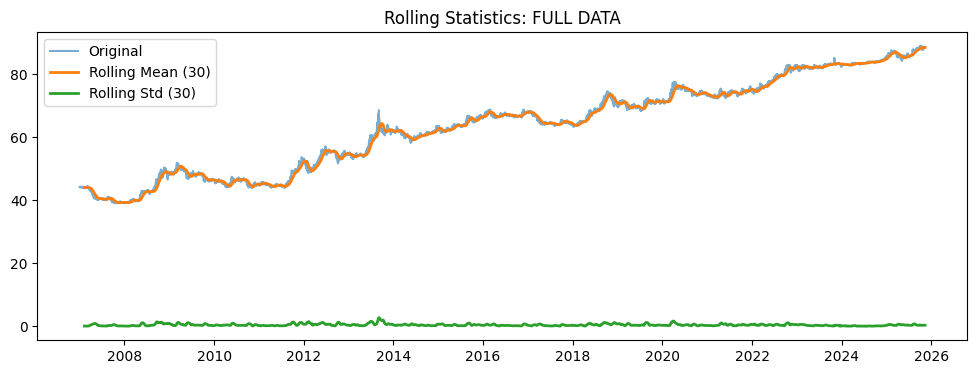

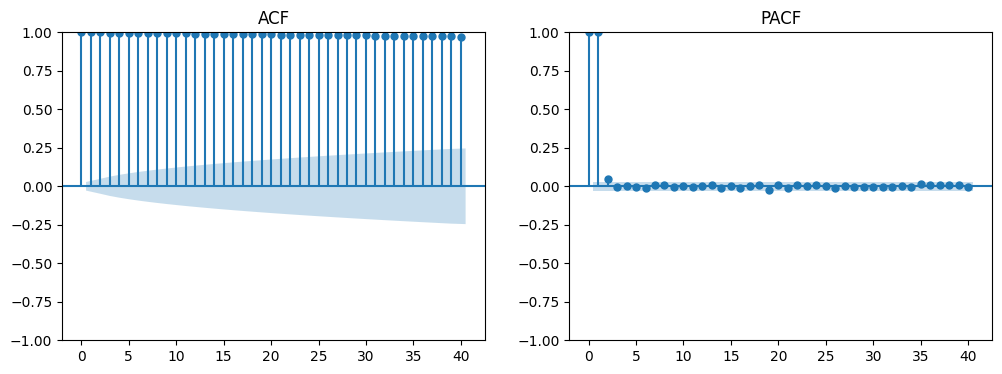


STATISTICAL ANALYSIS: REGIME 1

--- BASIC STATISTICS ---
Mean: 44.669
Std: 3.408
Coeff of Variation: 0.076

--- DISTRIBUTION SHAPE ---
Skewness: -0.152
Kurtosis: -1.115
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 0.6990
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


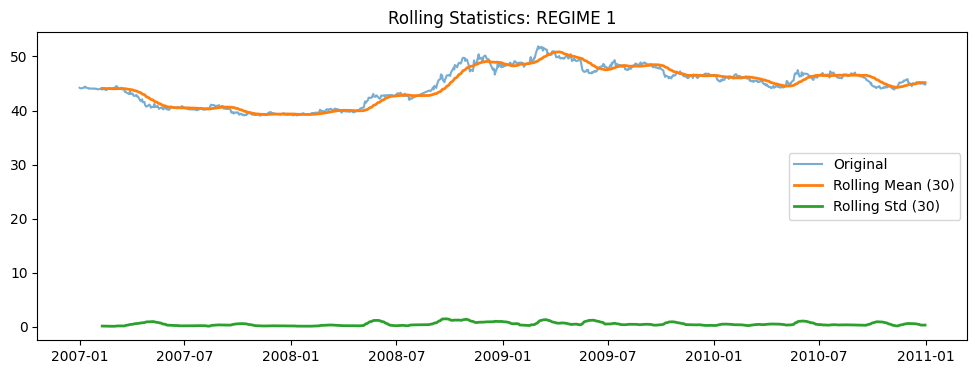

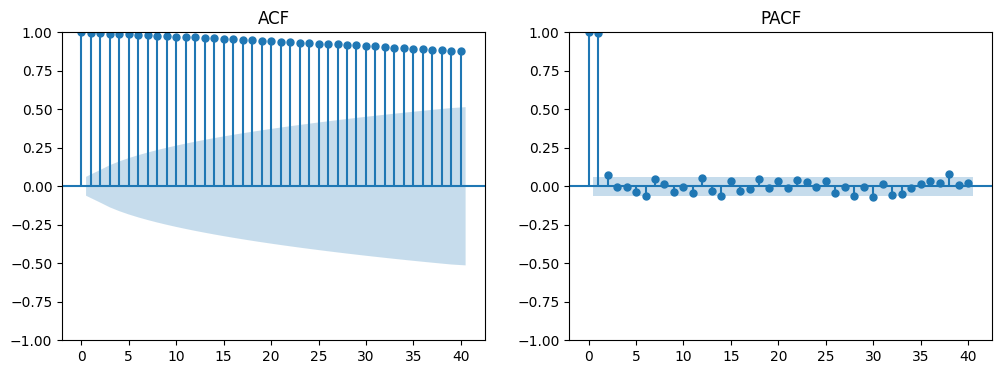


STATISTICAL ANALYSIS: REGIME 2

--- BASIC STATISTICS ---
Mean: 61.654
Std: 7.628
Coeff of Variation: 0.124

--- DISTRIBUTION SHAPE ---
Skewness: -0.766
Kurtosis: -0.309
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 0.4123
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


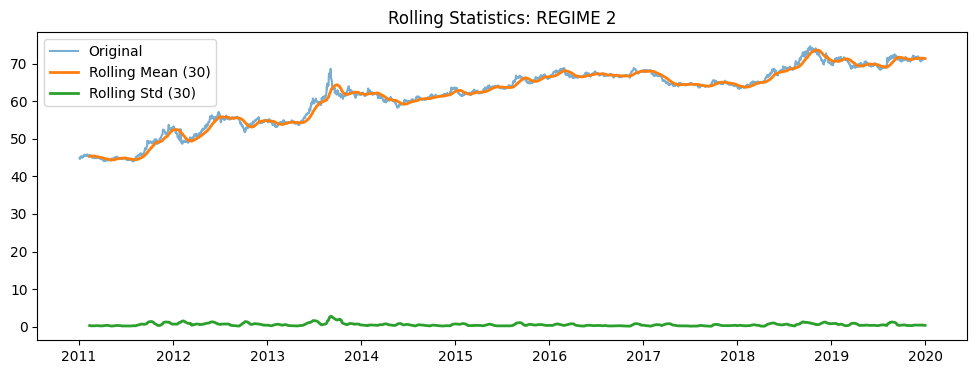

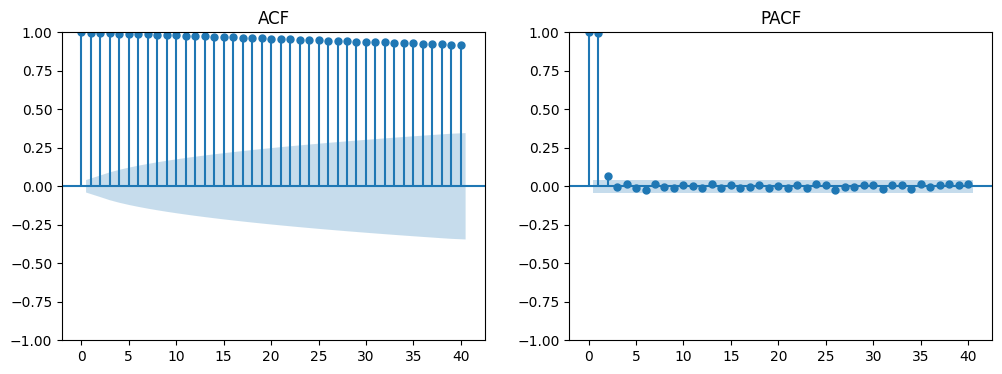


STATISTICAL ANALYSIS: REGIME 3

--- BASIC STATISTICS ---
Mean: 74.080
Std: 1.321
Coeff of Variation: 0.018

--- DISTRIBUTION SHAPE ---
Skewness: -0.189
Kurtosis: -0.054
Jarque–Bera p-value: 0.2053

--- STATIONARITY TESTS ---
ADF p-value: 0.0486
KPSS p-value: 0.1000


C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


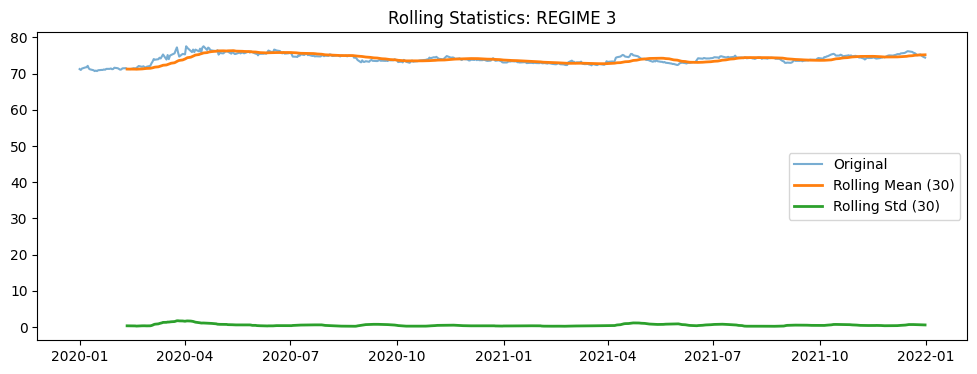

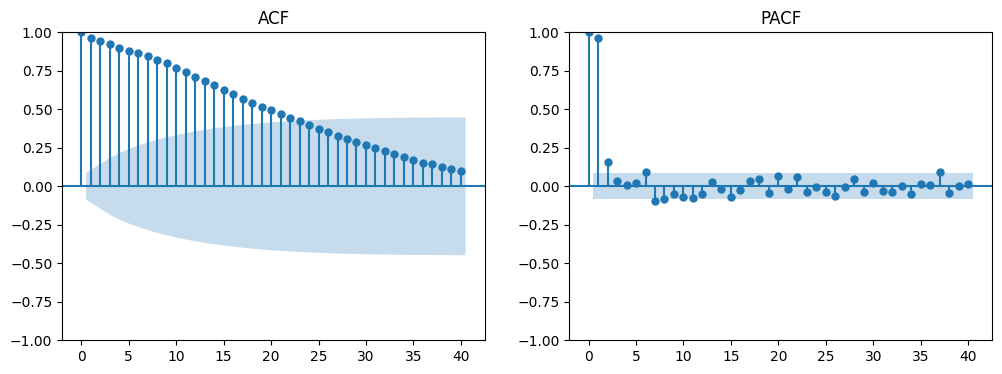


STATISTICAL ANALYSIS: REGIME 4

--- BASIC STATISTICS ---
Mean: 82.746
Std: 3.264
Coeff of Variation: 0.039

--- DISTRIBUTION SHAPE ---
Skewness: -0.698
Kurtosis: 0.413
Jarque–Bera p-value: 0.0000

--- STATIONARITY TESTS ---
ADF p-value: 0.2281
KPSS p-value: 0.0100


C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\1263523401.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_p = kpss(series, regression="c")[1]


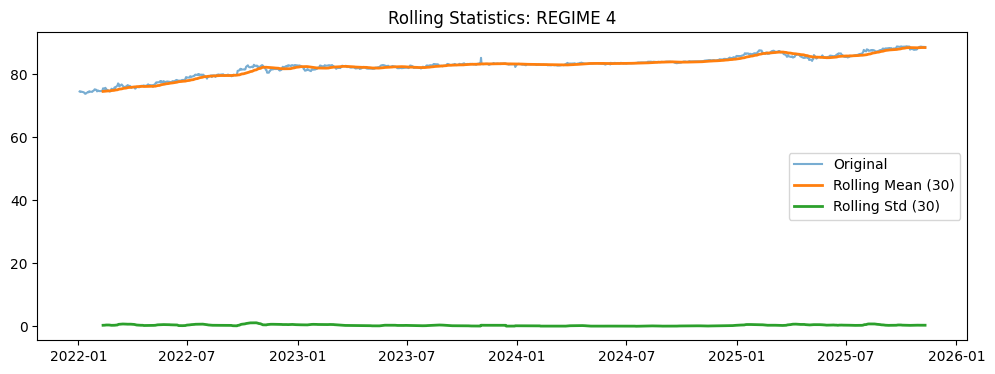

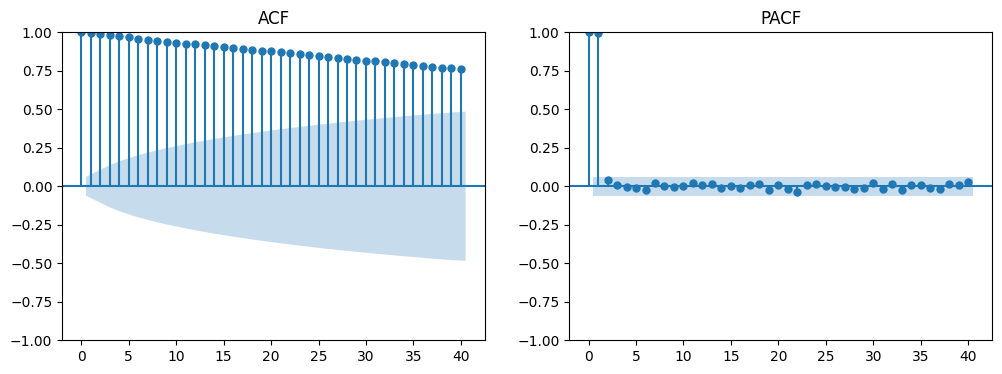

In [9]:
analyze_timeseries(df,  target="Close", name="FULL DATA")
analyze_timeseries(df1, target="Close", name="REGIME 1")
analyze_timeseries(df2, target="Close", name="REGIME 2")
analyze_timeseries(df3, target="Close", name="REGIME 3")
analyze_timeseries(df4, target="Close", name="REGIME 4")


In [10]:
def get_stats(df, target="Close"):
    s = df[target].dropna()

    stats = {}

    # Basic statistics
    stats["Mean"] = s.mean()
    stats["Std"]  = s.std()
    stats["CV"]   = s.std() / s.mean()

    # Distribution shape
    stats["Skewness"] = skew(s)
    stats["Kurtosis"] = kurtosis(s, fisher=True)

    # Normality
    stats["JB_pvalue"] = jarque_bera(s)[1]

    # Stationarity
    stats["ADF_pvalue"] = adfuller(s)[1]

    try:
        stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
    except:
        stats["KPSS_pvalue"] = np.nan

    return stats


In [11]:
results = pd.DataFrame({
    "FULL_DATA": get_stats(df),
    "DF1": get_stats(df1),
    "DF2": get_stats(df2),
    "DF3": get_stats(df3),
    "DF4": get_stats(df4)
})

results = results.round(4)
results


C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stats["KPSS_pvalue"] = kpss(s, regression="c")[1]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_49488\995538300.py:22: InterpolationWarning: The test statistic is outside of the range of p-values av

,FULL_DATA,DF1,DF2,DF3,DF4
Mean,63.7632,44.6690,61.6539,74.0796,82.7461
Std,14.0099,3.4085,7.6279,1.3211,3.2638
CV,0.2197,0.0763,0.1237,0.0178,0.0394
Skewness,-0.1061,-0.1519,-0.7661,-0.1887,-0.6976
Kurtosis,-1.1280,-1.1148,-0.3088,-0.0539,0.4127
JB_pvalue,0.0000,0.0000,0.0000,0.2053,0.0000
ADF_pvalue,0.9363,0.6990,0.4123,0.0486,0.2281
KPSS_pvalue,0.0100,0.0100,0.0100,0.1000,0.0100
